<a href="https://colab.research.google.com/github/FerneyEcheverri/web-scraping-totto/blob/main/notebooks/EA1_Proyecto_Totto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evidencia de aprendizaje 1 — Web scraping y análisis de Totto Colombia
**Fuente:** https://co.totto.com/  
**Objetivo:** inventariar categorías y subcategorías públicas, extraer fichas de productos y analizar precios, descuentos, marcas, disponibilidad y atributos.  
**Advertencia:** el sitio puede restringir consultas automatizadas. Este cuaderno no evade bloqueos, CAPTCHA ni autenticación; detiene la extracción ante respuestas 403/429. Los resultados son observaciones del catálogo público en la fecha de ejecución, no ventas reales.

In [ ]:
!pip -q install requests beautifulsoup4 pandas matplotlib seaborn openpyxl tqdm

In [ ]:
import requests, pandas as pd, numpy as np, re, time, json, random, matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from datetime import datetime, timezone
from IPython.display import display
BASE='https://co.totto.com'
S=requests.Session(); S.headers.update({'User-Agent':'ProyectoAcademicoColab/1.0 (investigacion educativa; contacto por navegador)', 'Accept':'application/json, text/html;q=0.9'})
PAUSA=1.5
FECHA=datetime.now().astimezone().isoformat(timespec='seconds')
def obtener(url, params=None):
    try:
        r=S.get(url,params=params,timeout=25)
        if r.status_code in (403,429):
            print(f'Acceso limitado ({r.status_code}) en {r.url}. Se detiene esta consulta; no se intentará eludir la restricción.')
            return None
        r.raise_for_status(); time.sleep(PAUSA); return r
    except requests.RequestException as e:
        print('Error de acceso:',str(e)[:180]); return None
print('Fecha de captura:',FECHA)

Fecha de captura: 2026-10-24T22:52:34+00:00


## 1. Descubrimiento de pestañas y categorías
Totto muestra menús como **Morrales, Mujer, Hombre, Niña, Niño, Viaje, Mascotas, Personajes y Accesorios**. El cuaderno intenta obtener la jerarquía completa desde el catálogo público VTEX; si no está disponible, usa enlaces visibles de navegación como respaldo. No confundir campañas temporales con categorías permanentes.

In [ ]:
r=obtener(BASE+'/api/catalog_system/pub/category/tree/5')
jerarquia=[]
if r is not None:
    try: jerarquia=r.json() if isinstance(r.json(),list) else []
    except ValueError: pass

def aplanar(nodos,padre='',nivel=1):
    filas=[]
    for x in nodos:
        nombre=x.get('name',''); ruta=x.get('url','')
        filas.append({'categoria':nombre,'categoria_padre':padre,'nivel':nivel,'id_categoria':x.get('id'),'url_categoria':urljoin(BASE,ruta) if ruta else None})
        filas.extend(aplanar(x.get('children') or [],nombre,nivel+1))
    return filas
categorias=pd.DataFrame(aplanar(jerarquia))
if categorias.empty:
    r=obtener(BASE)
    if r is not None:
        sopa=BeautifulSoup(r.text,'html.parser'); candidatos=[]
        for a in sopa.select('a[href]'):
            href=urljoin(BASE,a['href']); nombre=a.get_text(' ',strip=True)
            if href.startswith(BASE+'/') and nombre and len(nombre)<60:
                candidatos.append({'categoria':nombre,'categoria_padre':'Navegación visible','nivel':1,'id_categoria':None,'url_categoria':href.split('?')[0]})
        categorias=pd.DataFrame(candidatos).drop_duplicates(subset=['url_categoria']) if candidatos else pd.DataFrame(columns=['categoria','categoria_padre','nivel','id_categoria','url_categoria'])
print('Categorías y subcategorías identificadas:',len(categorias)); display(categorias.head(35))

Categorías y subcategorías identificadas: 269


,categoria,categoria_padre,nivel,id_categoria,url_categoria
0,Hombre,,1,1,https://co.totto.com/hombre
1,Accesorios,Hombre,2,14,https://co.totto.com/hombre/accesorios
2,billeteras,Accesorios,3,65,https://co.totto.com/hombre/accesorios/billeteras
3,gorras,Accesorios,3,66,https://co.totto.com/hombre/accesorios/gorras
4,gorros-para-hombre,Accesorios,3,67,https://co.totto.com/hombre/accesorios/gorros-...
5,cartucheras,Accesorios,3,68,https://co.totto.com/hombre/accesorios/cartuch...
6,loncheras,Accesorios,3,69,https://co.totto.com/hombre/accesorios/loncheras
7,canguros,Accesorios,3,70,https://co.totto.com/hombre/accesorios/canguros
8,gafas-de-sol,Accesorios,3,71,https://co.totto.com/hombre/accesorios/gafas-d...
9,relojes,Accesorios,3,72,https://co.totto.com/hombre/accesorios/relojes


## 2. Recolección por categoría, con paginación y control de carga
La API pública de búsqueda VTEX, cuando esté habilitada, permite recuperar registros con nombres, referencias, descripciones, categorías, precios e inventario público. Se aplica un **límite configurable** para evitar consultas masivas; cada categoría se procesa de forma independiente. Si la API no responde, el resultado quedará vacío y se documentará la limitación en vez de fabricar registros.

In [ ]:
MAX_CATEGORIAS=30       # Ajusta después de comprobar permisos
MAX_PRODUCTOS_CATEGORIA=100  # 2 páginas de hasta 50
TAM_LOTE=50
# Solo categorías principales por defecto. Cambia a False para incluir subcategorías (más solicitudes y duplicados).
SOLO_PRINCIPALES=True
seleccion=categorias[categorias['nivel'].eq(1)].copy() if SOLO_PRINCIPALES else categorias.copy()
seleccion=seleccion.head(MAX_CATEGORIAS)
print('Categorías a procesar:',len(seleccion))

Categorías a procesar: 18


In [ ]:
def precio_de_item(item):
    sellers=item.get('sellers') or []
    oferta=(sellers[0].get('commertialOffer') or {}) if sellers else {}
    return oferta.get('Price'),oferta.get('ListPrice'),oferta.get('AvailableQuantity'),oferta.get('IsAvailable')

def registro(p, categoria_consulta):
    items=p.get('items') or []
    item=items[0] if items else {}
    precio,lista,stock,disponible=precio_de_item(item)
    specs={}
    for g in p.get('specificationGroups') or []:
        for s in g.get('specifications') or []:
            specs[s.get('name','')]=', '.join(map(str,s.get('values') or []))
    return {'id_producto':p.get('productId'),'referencia':p.get('productReference'),'nombre':p.get('productName'),
      'marca':p.get('brand'),'categoria_consulta':categoria_consulta,'categorias_producto':' | '.join(p.get('categories') or []),
      'descripcion':BeautifulSoup(p.get('description') or '','html.parser').get_text(' ',strip=True),
      'precio_cop':precio,'precio_lista_cop':lista,'stock_publicado':stock,'disponible':disponible,
      'sku':item.get('itemId'),'ean':item.get('ean'),'atributos_json':json.dumps(specs,ensure_ascii=False),
      'url_producto':urljoin(BASE,p.get('link') or ''),'url_imagen':((item.get('images') or [{}])[0]).get('imageUrl'),
      'fecha_captura':FECHA}

registros=[]; estado=[]; detener=False
for _,cat in seleccion.iterrows():
    nombre=str(cat['categoria']); ident=cat['id_categoria']; ruta=cat['url_categoria']
    if pd.notna(ident):
        endpoint=BASE+'/api/catalog_system/pub/products/search/'
        filtro={'fq':'C:'+str(int(ident))}
    else:
        # Respaldo: ruta de categoría VTEX. Puede no funcionar para todas las tiendas.
        endpoint=BASE+'/api/catalog_system/pub/products/search/'
        filtro={'fq':'H:'+str(ruta).replace(BASE+'/','')}
    encontrados=0; motivo='OK'
    for inicio in range(0,MAX_PRODUCTOS_CATEGORIA,TAM_LOTE):
        params={**filtro,'_from':inicio,'_to':min(inicio+TAM_LOTE-1,MAX_PRODUCTOS_CATEGORIA-1)}
        r=obtener(endpoint,params)
        if r is None:
            motivo='API no accesible o bloqueada'; break
        try: productos=r.json()
        except ValueError: motivo='Respuesta no JSON'; break
        if not isinstance(productos,list): motivo='Formato no esperado'; break
        for p in productos: registros.append(registro(p,nombre))
        encontrados+=len(productos)
        if len(productos)<TAM_LOTE: break
    estado.append({'categoria':nombre,'productos_recuperados':encontrados,'estado':motivo})
    if motivo!='OK' and encontrados==0:
        print('Categoría sin acceso:',nombre, motivo)
productos=pd.DataFrame(registros)
log=pd.DataFrame(estado)
print('Filas recopiladas:',len(productos)); display(log); display(productos.head() if not productos.empty else pd.DataFrame({'aviso':['No se extrajeron productos. Verificar el estado de acceso; no hay datos para analizar.']}))

Filas recopiladas: 1101


,categoria,productos_recuperados,estado
0,Hombre,100,OK
1,Mujer,100,OK
2,nino,100,OK
3,Morrales,100,OK
4,Accesorios,100,OK
5,viaje,100,OK
6,Proteccion,0,OK
7,Hogar,0,OK
8,Mascotas,49,OK
9,Somos-Colombia,0,OK


,id_producto,referencia,nombre,marca,categoria_consulta,categorias_producto,descripcion,precio_cop,precio_lista_cop,stock_publicado,disponible,sku,ean,atributos_json,url_producto,url_imagen,fecha_captura
0,35861,MA04IND962-26100-Z9G,"Morral Ejecutivo Porta PC 14"" Osaka Azul Unisex",Totto,Hombre,/unisex/ | /Mujer/ | /Mujer/Morrales/ | /Hombr...,¡Lleva tu equipo con comodidad y funcionalidad...,97900.0,139900.0,99999,True,66777,7704682193120,{},https://co.totto.com/morral-ejecutivo-porta-pc...,https://tottoco.vteximg.com.br/arquivos/ids/67...,2026-10-24T22:52:34+00:00
1,35693,MA04TKI005-26160-N01,"Morral Universitario Trik 2.0 Porta PC 14"" Negro",Totto,Hombre,/unisex/ | /Mujer/ | /Mujer/Morrales/ | /Hombr...,El morral universitario Trik 2.0 integra un co...,99900.0,99900.0,99999,True,66609,7704682209302,{},https://co.totto.com/morral-universitario-trik...,https://tottoco.vteximg.com.br/arquivos/ids/67...,2026-10-24T22:52:34+00:00
2,32893,MA04IND962-25200-N01,"Morral Ejecutivo Porta PC 15.4"" Osaka Negro Un...",Totto,Hombre,/unisex/ | /Morrales/ | /Morrales/porta-pc/ | ...,¡Lleva tu equipo con comodidad y funcionalidad...,97900.0,139900.0,99999,True,61167,7704682069258,{},https://co.totto.com/morral-ejecutivo-porta-pc...,https://tottoco.vteximg.com.br/arquivos/ids/67...,2026-10-24T22:52:34+00:00
3,36392,MA04IND919-26160-Z9G,"Morral Universitario Cloud Porta PC 14"" Azul",Totto,Hombre,/unisex/ | /Mujer/ | /Mujer/Morrales/ | /Hombr...,¡Organiza tu día con el morral universitario C...,129900.0,129900.0,99999,True,67357,7704682209241,{},https://co.totto.com/morral-universitario-clou...,https://tottoco.vteximg.com.br/arquivos/ids/67...,2026-10-24T22:52:34+00:00
4,35099,AC61IND070-2610Z-Z9G,Lonchera Térmica Volt Mediana Azul,Totto,Hombre,/Hombre/Accesorios/loncheras/ | /Hombre/Acceso...,¡Conserva tus alimentos frescos por más tiempo...,39900.0,59900.0,100,True,65577,7704682205649,{},https://co.totto.com/lonchera-termica-volt-med...,https://tottoco.vteximg.com.br/arquivos/ids/64...,2026-10-24T22:52:34+00:00


## 3. Limpieza y variables derivadas
Un mismo producto puede aparecer en varias pestañas. Se conserva una tabla de apariciones por categoría y una tabla única por identificador. Los precios nulos **no** se reemplazan por cero.

In [ ]:
if not productos.empty:
    productos['precio_cop']=pd.to_numeric(productos['precio_cop'],errors='coerce')
    productos['precio_lista_cop']=pd.to_numeric(productos['precio_lista_cop'],errors='coerce')
    productos['descuento_pct']=np.where((productos['precio_lista_cop']>0)&(productos['precio_cop'].notna()),
       (1-productos['precio_cop']/productos['precio_lista_cop'])*100,np.nan)
    productos['descuento_pct']=productos['descuento_pct'].clip(lower=0,upper=100)
    unicos=productos.drop_duplicates(subset=['id_producto']).copy()
    print('Productos únicos:',len(unicos),'| Apariciones en categorías:',len(productos))
    display(unicos[['nombre','precio_cop','precio_lista_cop','descuento_pct','disponible']].head(15))
else:
    unicos=productos.copy()
    print('Sin datos reales; se omiten cálculos para evitar conclusiones ficticias.')

Productos únicos: 732 | Apariciones en categorías: 1101


,nombre,precio_cop,precio_lista_cop,descuento_pct,disponible
0,"Morral Ejecutivo Porta PC 14"" Osaka Azul Unisex",97900.0,139900.0,30.021444,True
1,"Morral Universitario Trik 2.0 Porta PC 14"" Negro",99900.0,99900.0,0.000000,True
2,"Morral Ejecutivo Porta PC 15.4"" Osaka Negro Un...",97900.0,139900.0,30.021444,True
3,"Morral Universitario Cloud Porta PC 14"" Azul",129900.0,129900.0,0.000000,True
4,Lonchera Térmica Volt Mediana Azul,39900.0,59900.0,33.388982,True
5,"Morral Ejecutivo Porta PC 16"" Wivetto 2.0 Azul...",127900.0,159900.0,20.012508,True
6,"Morral Antirrobo Porta PC 14"" Twill Azul Unisex",84900.0,169900.0,50.029429,True
7,Billetera para Hombre Contrast Can con RFID Bl...,29900.0,59900.0,50.083472,True
8,Portacomidas Magu Verde,23900.0,59900.0,60.100167,True
9,"Morral Ejecutivo Porta PC 16"" Wivetto 2.0 Negr...",127900.0,159900.0,20.012508,True


## 4. Análisis de **cada pestaña/categoría**
Para cada categoría: cantidad de registros, productos únicos, mínimo, máximo, mediana, promedio, descuentos, disponibilidad y distribución de precios. Se genera además un texto automático por categoría basado **solo** en datos observados.

In [ ]:
if not productos.empty:
    resumen=(productos.groupby('categoria_consulta',dropna=False).agg(
        registros=('id_producto','size'),productos_unicos=('id_producto','nunique'),
        precio_min=('precio_cop','min'),precio_mediano=('precio_cop','median'),precio_promedio=('precio_cop','mean'),
        precio_max=('precio_cop','max'),descuento_promedio_pct=('descuento_pct','mean'),
        disponibles=('disponible',lambda x: int((x==True).sum()))).reset_index())
    resumen['porcentaje_disponibles']=100*resumen['disponibles']/resumen['registros']
    display(resumen.sort_values('productos_unicos',ascending=False))
    for _,x in resumen.iterrows():
        print(f"{x['categoria_consulta']}: {int(x['productos_unicos'])} productos únicos; precio mediano COP ${x['precio_mediano']:,.0f}; rango COP ${x['precio_min']:,.0f}–${x['precio_max']:,.0f}; descuento promedio {x['descuento_promedio_pct']:.1f}% (si está disponible).")
else:
    resumen=pd.DataFrame(); print('No es posible analizar categorías sin registros extraídos.')

,categoria_consulta,registros,productos_unicos,precio_min,precio_mediano,precio_promedio,precio_max,descuento_promedio_pct,disponibles,porcentaje_disponibles
0,Accesorios,100,100,1000.0,37400.0,37670.000000,79900.0,39.436649,100,100.000000
2,Hombre,100,100,1000.0,62900.0,76748.000000,319900.0,28.728765,93,93.000000
5,Mujer,100,100,1000.0,69900.0,72458.000000,229900.0,32.940273,94,94.000000
4,Morrales,100,100,53900.0,95900.0,121700.000000,319900.0,30.931890,100,100.000000
8,nina,100,100,1000.0,24900.0,37011.000000,209900.0,27.413872,98,98.000000
6,Ropa,100,100,24900.0,108900.0,111280.000000,249900.0,21.845333,69,69.000000
13,viaje,100,100,3500.0,144900.0,183212.000000,569900.0,21.460631,100,100.000000
12,unisex,100,100,1000.0,51900.0,60953.000000,269900.0,22.880569,100,100.000000
9,nino,100,100,1000.0,37900.0,50511.000000,299900.0,26.723439,96,96.000000
10,parches,100,100,2500.0,2500.0,2624.000000,14900.0,0.000000,100,100.000000


Accesorios: 100 productos únicos; precio mediano COP $37,400; rango COP $1,000–$79,900; descuento promedio 39.4% (si está disponible).
Bolsos: 15 productos únicos; precio mediano COP $79,900; rango COP $29,900–$159,900; descuento promedio 27.6% (si está disponible).
Hombre: 100 productos únicos; precio mediano COP $62,900; rango COP $1,000–$319,900; descuento promedio 28.7% (si está disponible).
Mascotas: 49 productos únicos; precio mediano COP $49,900; rango COP $9,900–$164,900; descuento promedio 50.4% (si está disponible).
Morrales: 100 productos únicos; precio mediano COP $95,900; rango COP $53,900–$319,900; descuento promedio 30.9% (si está disponible).
Mujer: 100 productos únicos; precio mediano COP $69,900; rango COP $1,000–$229,900; descuento promedio 32.9% (si está disponible).
Ropa: 100 productos únicos; precio mediano COP $108,900; rango COP $24,900–$249,900; descuento promedio 21.8% (si está disponible).
Tarjeta-Regalo: 7 productos únicos; precio mediano COP $120,000; rango

## 5. Análisis individual de **cada producto**
Se produce una ficha por producto con categoría, SKU, descripción, precio, descuento, disponibilidad, atributos técnicos y enlace. Para evitar saturar la pantalla, se muestra una muestra y se exportan **todas** las fichas a Excel/CSV.

In [ ]:
if not unicos.empty:
    fichas=unicos.copy()
    fichas['analisis_individual']=fichas.apply(lambda x: (
        f"Producto: {x['nombre']}. Categorías: {x['categorias_producto']}. "
        f"Precio publicado: {('COP $'+format(x['precio_cop'],',.0f')) if pd.notna(x['precio_cop']) else 'no disponible'}. "
        f"Descuento: {format(x['descuento_pct'],'.1f')+'%' if pd.notna(x['descuento_pct']) else 'sin dato verificable'}. "
        f"Disponibilidad publicada: {x['disponible']}. "
        f"Descripción: {(x['descripcion'] or '')[:350]}. "
        f"Especificaciones: {x['atributos_json'][:400]}."),axis=1)
    display(fichas[['nombre','categoria_consulta','precio_cop','analisis_individual']].head(10))
else: fichas=unicos.copy()

,nombre,categoria_consulta,precio_cop,analisis_individual
0,"Morral Ejecutivo Porta PC 14"" Osaka Azul Unisex",Hombre,97900.0,"Producto: Morral Ejecutivo Porta PC 14"" Osaka ..."
1,"Morral Universitario Trik 2.0 Porta PC 14"" Negro",Hombre,99900.0,Producto: Morral Universitario Trik 2.0 Porta ...
2,"Morral Ejecutivo Porta PC 15.4"" Osaka Negro Un...",Hombre,97900.0,"Producto: Morral Ejecutivo Porta PC 15.4"" Osak..."
3,"Morral Universitario Cloud Porta PC 14"" Azul",Hombre,129900.0,Producto: Morral Universitario Cloud Porta PC ...
4,Lonchera Térmica Volt Mediana Azul,Hombre,39900.0,Producto: Lonchera Térmica Volt Mediana Azul. ...
5,"Morral Ejecutivo Porta PC 16"" Wivetto 2.0 Azul...",Hombre,127900.0,"Producto: Morral Ejecutivo Porta PC 16"" Wivett..."
6,"Morral Antirrobo Porta PC 14"" Twill Azul Unisex",Hombre,84900.0,"Producto: Morral Antirrobo Porta PC 14"" Twill ..."
7,Billetera para Hombre Contrast Can con RFID Bl...,Hombre,29900.0,Producto: Billetera para Hombre Contrast Can c...
8,Portacomidas Magu Verde,Hombre,23900.0,Producto: Portacomidas Magu Verde. Categorías:...
9,"Morral Ejecutivo Porta PC 16"" Wivetto 2.0 Negr...",Hombre,127900.0,"Producto: Morral Ejecutivo Porta PC 16"" Wivett..."


## 6. Visualizaciones e interpretación
Las gráficas reflejan únicamente productos recuperados, no el catálogo completo salvo que se compruebe cobertura exhaustiva.

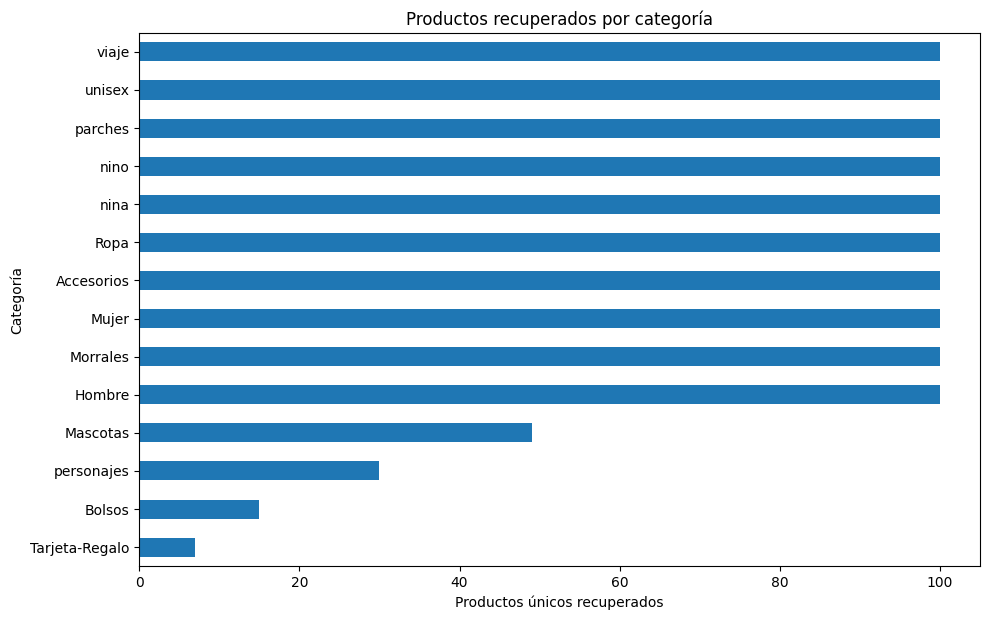

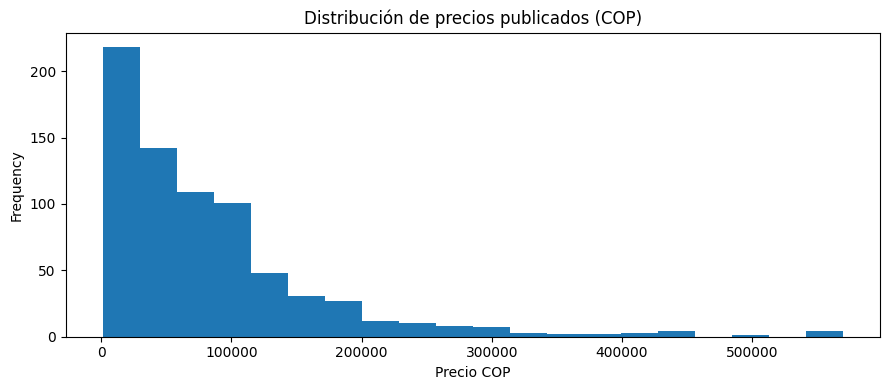

In [ ]:
if not resumen.empty:
    ax=resumen.sort_values('productos_unicos').plot.barh(x='categoria_consulta',y='productos_unicos',legend=False,figsize=(10,max(4,len(resumen)*.45)))
    ax.set(xlabel='Productos únicos recuperados',ylabel='Categoría',title='Productos recuperados por categoría');plt.tight_layout();plt.show()
    datos=unicos.dropna(subset=['precio_cop'])
    if not datos.empty:
        datos['precio_cop'].plot.hist(bins=min(20,max(5,len(datos)//5)),figsize=(9,4),title='Distribución de precios publicados (COP)')
        plt.xlabel('Precio COP');plt.tight_layout();plt.show()
else: print('Gráficos no generados: extracción sin resultados.')

## 7. Exportación y conclusiones
Se exportan los datos sin inventar resultados. El archivo `totto_analisis.xlsx` incluye pestañas para categorías, apariciones de productos, fichas individuales, resumen y estado de las consultas. Los registros corresponden a la fecha indicada y pueden cambiar.

In [ ]:
with pd.ExcelWriter('totto_analisis.xlsx',engine='openpyxl') as w:
    categorias.to_excel(w,'Mapa_categorias',index=False)
    log.to_excel(w,'Estado_extraccion',index=False)
    productos.to_excel(w,'Productos_por_categoria',index=False)
    fichas.to_excel(w,'Fichas_por_producto',index=False)
    resumen.to_excel(w,'Resumen_categorias',index=False)
productos.to_csv('totto_productos.csv',index=False,encoding='utf-8-sig')
print('Archivos generados: totto_analisis.xlsx, totto_productos.csv')
try:
    from google.colab import files
    files.download('totto_analisis.xlsx'); files.download('totto_productos.csv')
except ImportError: print('Descarga los archivos desde el explorador del entorno.')

/tmp/ipykernel_4628/4119692650.py:2: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  categorias.to_excel(w,'Mapa_categorias',index=False)
/tmp/ipykernel_4628/4119692650.py:3: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  log.to_excel(w,'Estado_extraccion',index=False)
/tmp/ipykernel_4628/4119692650.py:4: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  productos.to_excel(w,'Productos_por_categoria',index=False)
/tmp/ipykernel_4628/4119692650.py:5: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  fichas.to_excel(w,'Fichas_por_producto',index=False)
/tmp/ipykernel_4628/4119692650.py:6: FutureWarning: Starting with pandas version 3.0 all a

Archivos generados: totto_analisis.xlsx, totto_productos.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Analisis de un producto del catalogo
Se filtra el articulo Morral ejecutivo en el cual se encontró 17 referencias. todas con disponibilidad publicada «Sí». Los precios observados oscilan entre  84.900   y 319.900; la mediana es 149.900  y el promedio  162.900. De las 17 referencias. 13 muestran descuentos positivos y 4 figuran sin descuento; el mayor descuento registrado es 50.0%.

In [ ]:
import pandas as pd
from IPython.display import display

# Filtrar productos únicos que contengan 'ejecutivo' en el nombre o descripción
filtro_ejecutivos = unicos['nombre'].str.contains('ejecutivo', case=False, na=False) | unicos['descripcion'].str.contains('ejecutivo', case=False, na=False)
morrales_ejecutivos = unicos[filtro_ejecutivos].copy()

# Seleccionar y renombrar las columnas solicitadas incluyendo la categoría de consulta
tabla_ejecutivos = morrales_ejecutivos[[
    'nombre',
    'categoria_consulta',
    'descripcion',
    'precio_cop',
    'descuento_pct',
    'disponible'
]].copy()

# Dar un formato amigable a las columnas para la visualización
tabla_ejecutivos['precio_cop'] = tabla_ejecutivos['precio_cop'].apply(lambda x: f"COP ${x:,.0f}" if pd.notna(x) else "No disponible")
tabla_ejecutivos['descuento_pct'] = tabla_ejecutivos['descuento_pct'].apply(lambda x: f" {x:.1f}%" if pd.notna(x) and x > 0 else "Sin descuento")
tabla_ejecutivos['disponible'] = tabla_ejecutivos['disponible'].map({True: 'Sí', False: 'No'})

tabla_ejecutivos.columns = ['Nombre', 'Categoría de Consulta', 'Descripción', 'Precio', 'Descuento', 'Disponible']

print(f'Se encontraron {len(tabla_ejecutivos)} morrales ejecutivos.')
display(tabla_ejecutivos)

Se encontraron 17 morrales ejecutivos.


,Nombre,Categoría de Consulta,Descripción,Precio,Descuento,Disponible
0,"Morral Ejecutivo Porta PC 14"" Osaka Azul Unisex",Hombre,¡Lleva tu equipo con comodidad y funcionalidad...,"COP $97,900",30.0%,Sí
2,"Morral Ejecutivo Porta PC 15.4"" Osaka Negro Un...",Hombre,¡Lleva tu equipo con comodidad y funcionalidad...,"COP $97,900",30.0%,Sí
5,"Morral Ejecutivo Porta PC 16"" Wivetto 2.0 Azul...",Hombre,¡Eleva tu experiencia laboral con este morral ...,"COP $127,900",20.0%,Sí
9,"Morral Ejecutivo Porta PC 16"" Wivetto 2.0 Negr...",Hombre,¡Eleva tu experiencia laboral con este morral ...,"COP $127,900",20.0%,Sí
24,"Morral Ejecutivo Porta PC 16"" Daytona Azul Hombre",Hombre,¡Hazlo parte de tu rutina! El morral ejecutivo...,"COP $134,900",50.0%,Sí
34,"Morral Ejecutivo Porta PC 14"" Wivetto Negro Ho...",Hombre,¡Lleva todo lo que necesites a tu trabajo o un...,"COP $149,900",Sin descuento,Sí
49,"Morral Ejecutivo Porta PC 13"" Datar 2.0 Azul H...",Hombre,¡Ligero y cómodo para tus jornadas! El morral ...,"COP $99,900",41.2%,Sí
73,"Morral Ejecutivo Porta PC 16"" Slant Negro Hombre",Hombre,¡Optimiza tu rutina diaria con este morral par...,"COP $179,900",30.8%,Sí
91,"Morral Ejecutivo Porta PC 16"" Gtx 3.0 Negro Ho...",Hombre,"Avanza seguro con el Gtx 3.0, un morral para o...","COP $319,900",Sin descuento,Sí
191,"Morral Ejecutivo Porta PC 14"" Bow Morado Mujer",Mujer,¡Funcionalidad y diseño en un solo morral! Bow...,"COP $153,900",30.0%,Sí


**Ética y límites:** usar solamente datos públicos; no recolectar datos personales, no eludir medidas de seguridad, revisar términos del sitio y respetar límites de consulta. Si el acceso es denegado, solicitar autorización o utilizar un conjunto de datos autorizado.

**Referencias (APA 7):**
* Totto. (2026). *Tienda oficial Totto Colombia*. https://co.totto.com/
* Python Software Foundation. (s. f.). *Python documentation*. https://docs.python.org/3/
* Pandas development team. (s. f.). pandas documentation. https://pandas.pydata.org/docs/
* Beautiful Soup. (s. f.). Beautiful Soup documentation. https://www.crummy.com/software/BeautifulSoup/bs4/doc/
* Project Jupyter. (s. f.). Jupyter documentation. https://docs.jupyter.org/




